<hr style="border:2px solid #CC00FF;">

<!-- Contenedor ultra-compatible. Usamos 'height' en lugar de 'width' para lograr simetría visual -->
<p align="center">
    <a href="https://medellin.unal.edu.co" target="_blank">
        <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR9ItLTT_F-3Q30cu7ZCCoKmuFGBt22pe7pNA" height="75" alt="Logo UNAL">
    </a>
    &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;
    <a href="https://minaslap.net/?redirect=0" target="_blank">
        <img src="https://minaslap.net/pluginfile.php/1/core_admin/logo/0x200/1770226238/Logo%20MinasLAP-3%20%281%29.png" height="75" alt="Logo MinasLAP">
    </a>
    &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;
    <a href="https://micampus.unal.edu.co" target="_blank">
        <img src="https://micampus.unal.edu.co/pluginfile.php/1/theme_almondb/sliderimage1/1788871931/Slider_1.png" height="75" alt="Logo MiCampus">
    </a>
</p>

<!-- Títulos usando alineación clásica compatible con IDEs -->
<h1 align="center">Optimización e IA 2026-2S</h1>
<h2 align="center">Trabajo final</h2>
<h3 align="center">Optimización Bayesiana</h3>
<p align="center">
    Departamento de Ciencias de la Computación y de la Decisión<br>
    Facultad de Minas<br>
    Universidad Nacional de Colombia<br>
    Docente: Maria Constanza Torres Madronero
</p>

<div id="conte"></div>
<hr style="border:2px solid #CC00FF;">

**Elaborado por:** _Kevin Ferney Hidalgo Higuita_

**Correo:** _kfhidalgoh@unal.edu.co_

**Fecha de elaboración:** _30 de septiembre de 2026_

**Fecha última modificación:** _28 de septiembre de 2026_

**Repositorio:** [![GitHub Repository](https://img.shields.io/badge/repository-GitHub-181717.svg)](https://github.com/KevinHidalgoDS/optimizacion-ia)

*Nota: el tema del navegador para visualizar HTML puede afectar el comportamiento de la presentación.*

In [62]:
import sys

import matplotlib.pyplot as plt
from pathlib import Path

import numpy as np
import pandas as pd
from narwhals.dependencies import is_pandas_dataframe
from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from skopt import BayesSearchCV
import seaborn as sns
from src.utils import logger as log

logger = log.LOGGER
config = log.CONFIG
logger.info("Python %s on %s", sys.version, sys.platform)

%matplotlib inline
plt.style.use("ggplot")
rng = np.random.default_rng(123)

2026-10-09 17:46:20 [INFO] Python 3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)] on win32


Tercer caso de uso de la Propuesta de Transición a Machine Learning (Sección 3.3).
Clasifica el estado de los transmisores de nivel LT-051004A/B en 3 clases —
sano / deriva gradual / fallo duro — a partir del residual entre ambos sensores
y su tendencia reciente, para detectar una deriva ANTES de que dispare la alarma
binaria de "fallo de medida" que ya existe.

ARCHIVOS DE ENTRADA (los que exporta el botón "Detección de Anomalías de Sensor"
del Generador Automático de Datasets ML, en la pestaña EOP-05 del simulador):
    telemetria_anomalias_sensor_*.csv
    episodios_anomalias_sensor_*.csv

In [8]:
# Constantes
CLASES = ["sano", "deriva", "fallo_duro"]
ROLLING_WINDOW = 5  # muestras (25 s a 5 s/muestra)
FEATURES = ["ltA_medido", "ltB_medido", "lt_residual", "residual_roll_mean", "residual_slope"]
UMBRAL_BASELINE = 0.15  # m — el mismo umbral de aviso ya implementado en el simulador (sin histéresis, por simplicidad)
file_path = Path(config.paths.data.raw) / "telemetria.csv"
if not file_path.exists():
    from src.config import PROJECT_PATH
    file_path = PROJECT_PATH / config.paths.data.raw / "telemetria.csv"

## Funciones auxiliares

In [44]:
def cargar_y_preparar(path_telemetria: str|None, tel: pd.DataFrame|None, rolling_window: int = 10) -> pd.DataFrame:
    """
    Carga la telemetría y construye el target de 3 clases basado en la verdad de terreno.

    Utiliza las columnas exportadas por el simulador (sensorA_fallo, sensorB_fallo,
    sensorA_deriva_activa, sensorB_deriva_activa) para clasificar el estado sin necesidad
    de cruzar datos por tiempo contra un CSV externo de episodios.

    Args:
        path_telemetria (str): Ruta al archivo CSV que contiene la telemetría del simulador.
        tel (pd.DataFrame): dataframe previo.
        rolling_window (int, optional): Tamaño de la ventana móvil para el cálculo de
            medias y pendientes. Por defecto es 10.

    Returns:
        pd.DataFrame: DataFrame ordenado cronológicamente con la nueva columna 'label'
            (0: sano, 1: deriva, 2: fallo_duro) y características móviles calculadas.

    Raises:
        FileNotFoundError: Si el archivo especificado en `path_telemetria` no existe.
        pd.errors.EmptyDataError: Si el archivo CSV está vacío.
        ValueError: Si faltan columnas requeridas en el archivo cargado.
        Exception: Para capturar y registrar cualquier otro error crítico en tiempo de ejecución.
    """
    # =========================================================================
    # Bloque 1: Carga de datos y control de acceso al archivo
    # =========================================================================
    logger.info(f"Iniciando la carga de telemetría desde: {path_telemetria}")
    try:
        if path_telemetria:
            tel = pd.read_csv(path_telemetria)
            logger.debug(f"Archivo CSV cargado exitosamente. Dimensiones: {tel.shape}")
        if not isinstance(tel, pd.DataFrame):
            raise ValueError(
                "Se debe proporcionar 'path_telemetria' o un DataFrame válido en 'tel'."
            )
        logger.debug(f"DataFrame listo. Dimensiones: {tel.shape}")
    except FileNotFoundError as e:
        logger.error(f"No se encontró el archivo de telemetría en la ruta: {path_telemetria, e}")
        raise
    except pd.errors.EmptyDataError as e:
        logger.error(f"El archivo CSV de telemetría está completamente vacío: {path_telemetria, e}")
        raise
    except Exception as e:
        logger.critical(f"Error inesperado al intentar leer el CSV: {str(e)}")
        raise

    # =========================================================================
    # Bloque 2: Validación de esquema y datos requeridos
    # =========================================================================
    logger.debug("Validando la integridad del esquema de columnas.")
    requeridas = [
        "t",
        "ltA_medido",
        "ltB_medido",
        "lt_residual",
        "sensorA_fallo",
        "sensorB_fallo",
        "sensorA_deriva_activa",
        "sensorB_deriva_activa",
    ]
    faltantes = [c for c in requeridas if c not in tel.columns]

    if faltantes:
        mensaje_error = (
            f"Faltan columnas requeridas: {faltantes}. Este script necesita "
            f"telemetría generada con una versión del simulador que incluya "
            f"columnas de verdad de terreno de sensores."
        )
        logger.error(mensaje_error)
        raise ValueError(mensaje_error)

    # =========================================================================
    # Bloque 3: Procesamiento temporal y etiquetado de clases (Target)
    # =========================================================================
    def clase(row: pd.Series) -> int:
        """Determina la clase objetivo evaluando booleanos de la fila actual."""
        if row["sensorA_fallo"] or row["sensorB_fallo"]:
            return 2  # fallo_duro
        if row["sensorA_deriva_activa"] or row["sensorB_deriva_activa"]:
            return 1  # deriva
        return 0  # sano

    logger.info("Ordenando datos temporalmente y generando variable objetivo ('label').")
    try:
        tel = tel.sort_values("t").reset_index(drop=True)
        tel["label"] = tel.apply(clase, axis=1)
        logger.debug("Columna 'label' generada correctamente.")
    except KeyError as e:
        logger.error(f"Llave no encontrada durante la asignación de clases: {str(e)}")
        raise
    except Exception as e:
        logger.error(f"Error procesando la lógica de clases: {str(e)}")
        raise

    # =========================================================================
    # Bloque 4: Ingeniería de características (Feature Engineering)
    # =========================================================================
    logger.info(f"Calculando estadísticas de ventana móvil (window_size={rolling_window}).")
    try:
        # Promedio móvil del residual
        tel["residual_roll_mean"] = (
            tel["lt_residual"].rolling(window=rolling_window, min_periods=1).mean()
        )
        # Pendiente (diferencia) sobre la ventana
        tel["residual_slope"] = (
            tel["lt_residual"].diff(periods=rolling_window).fillna(0) / rolling_window
        )
        logger.debug("Cálculo de 'residual_roll_mean' y 'residual_slope' finalizado.")
    except TypeError as e:
        logger.warning(f"Error de tipos calculando ventanas móviles (revisar NaNs o strings): {e}")
        raise
    except Exception as e:
        logger.error(f"Fallo durante la ingeniería de características: {str(e)}")
        raise

    logger.info("La carga y preparación del DataFrame se completó con éxito.")
    return tel

def column_overview(data_frame: pd.DataFrame) -> pd.DataFrame:
    dtypes = data_frame.dtypes.astype(str).to_frame('dtype')
    missing_count = data_frame.isna().sum().to_frame('missing_count')
    unique_count = data_frame.nunique(dropna=False).to_frame('unique_count')
    col_overview = pd.concat([dtypes, missing_count, unique_count], axis=1)
    return col_overview

def codificar_variables_texto(df: pd.DataFrame, mapeo_ordinal: dict = None) -> pd.DataFrame:
    """
    Identifica las columnas de tipo string/object y las convierte a enteros en el mismo lugar.

    Permite mapear variables ordinales (con orden lógico) mediante un diccionario.
    Para las variables nominales (sin orden), aplica LabelEncoder automáticamente.

    Args:
        df (pd.DataFrame): DataFrame original con tipos de datos mixtos.
        mapeo_ordinal (dict, opcional): Diccionario con el orden específico para ciertas columnas.
            Ej: {'calidad': {'malo': 0, 'regular': 1, 'bueno': 2}}

    Returns:
        pd.DataFrame: DataFrame con las columnas de texto transformadas a numéricas (int).
    """
    # Trabajamos sobre una copia para no alterar el DataFrame original inadvertidamente
    df_procesado = df.copy()
    mapeo_ordinal = mapeo_ordinal or {}

    # Identificar columnas que son de tipo object o string
    columnas_texto = df_procesado.select_dtypes(include=['object', 'string']).columns

    for col in columnas_texto:
        # 1. Si la columna tiene un orden definido por el usuario (Ordinal)
        if col in mapeo_ordinal:
            df_procesado[col] = df_procesado[col].map(mapeo_ordinal[col])

            # Validar si quedaron valores nulos por categorías no mapeadas
            if df_procesado[col].isnull().any():
                raise ValueError(
                    f"Se encontraron categorías en la columna '{col}' que no están "
                    f"definidas en el diccionario de mapeo."
                )

        # 2. Si la columna no tiene orden (Nominal), codificar alfabéticamente
        else:
            encoder = LabelEncoder()
            # Convertimos a string primero por si hay valores mixtos/nulos
            df_procesado[col] = encoder.fit_transform(df_procesado[col].astype(str))

    # Forzar la conversión final a tipo entero
    for col in columnas_texto:
        df_procesado[col] = df_procesado[col].astype(int)

    return df_procesado

## Lectura de `telemetria.csv`

In [23]:
logger.info("Leyendo archivo desde: %s", file_path)
df = pd.read_csv(file_path)
logger.info("Archivo cargado exitosamente con dimensiones: %s", df.shape)

2026-10-09 16:40:45 [INFO] Leyendo archivo desde: D:\Proyectos\optimization-ai-labs\data\raw\telemetria.csv
2026-10-09 16:40:45 [INFO] Archivo cargado exitosamente con dimensiones: (518, 69)


Seleccionando columnas de interés

In [25]:
df_tel = cargar_y_preparar(path_telemetria=None, tel=df)

2026-10-09 16:41:03 [INFO] Iniciando la carga de telemetría desde: None
2026-10-09 16:41:03 [INFO] Ordenando datos temporalmente y generando variable objetivo ('label').
2026-10-09 16:41:03 [INFO] Calculando estadísticas de ventana móvil (window_size=10).
2026-10-09 16:41:03 [INFO] La carga y preparación del DataFrame se completó con éxito.


In [17]:
display(df_tel.head())

,t,levelA,levelB,levelShared,qTotal,inflow,inflow_real,cpbe71,autoMode,sn1,...,BEN-06_speed,BEN-06_flow,BEN-06_hours,BEN-06_mode,BEN-06_vib,BEN-06_temp,BEN-06_risk,label,residual_roll_mean,residual_slope
0,1,4.108,4.107,4.108,0.0,2.4,2.373,open,True,1,...,0,0.0,1036.5,auto,2.0,45.0,0.0,0,0.001000,0.0
1,6,4.145,4.156,4.150,0.0,2.4,2.366,open,True,1,...,0,0.0,1036.5,auto,2.0,45.0,0.0,0,0.006000,0.0
2,11,4.191,4.186,4.193,0.0,2.4,2.373,open,True,1,...,0,0.0,1036.5,auto,2.0,45.0,0.0,0,0.005667,0.0
3,16,4.231,4.234,4.236,0.0,2.4,2.407,open,True,1,...,0,0.0,1036.5,auto,2.0,45.0,0.0,0,0.005000,0.0
4,21,4.281,4.282,4.279,0.0,2.4,2.479,open,True,1,...,0,0.0,1036.5,auto,2.0,45.0,0.0,0,0.004200,0.0


In [27]:
column_overview(df_tel)

,dtype,missing_count,unique_count
t,int64,0,518
levelA,float64,0,417
levelB,float64,0,424
levelShared,float64,0,410
qTotal,float64,0,173
...,...,...,...
BEN-06_temp,float64,0,36
BEN-06_risk,float64,0,40
label,int64,0,3
residual_roll_mean,float64,0,264


In [28]:
df_tel['cpbe71'].unique()

<StringArray>
['open']
Length: 1, dtype: str

In [29]:
df_tel['fuente_nivel_activa'].unique()

<StringArray>
['MEDIO', 'LT-B']
Length: 2, dtype: str

In [30]:
df_tel['BEN-01_mode'].unique()

<StringArray>
['auto']
Length: 1, dtype: str

In [32]:
df_tel['BEN-01_state'].unique()

<StringArray>
['stopped', 'starting', 'running']
Length: 3, dtype: str

In [31]:
df_tel['BEN-02_state'].unique()

<StringArray>
['stopped', 'starting', 'running', 'stopping']
Length: 4, dtype: str

In [34]:
df_tel['BEN-02_mode'].unique()

<StringArray>
['auto']
Length: 1, dtype: str

In [35]:
df_tel['BEN-03_state'].unique()

<StringArray>
['stopped', 'starting', 'running', 'stopping']
Length: 4, dtype: str

In [36]:
df_tel['BEN-03_mode'].unique()

<StringArray>
['auto']
Length: 1, dtype: str

In [37]:
df_tel['BEN-04_state'].unique()

<StringArray>
['stopped', 'starting', 'running', 'stopping']
Length: 4, dtype: str

In [38]:
df_tel['BEN-04_mode'].unique()

<StringArray>
['auto']
Length: 1, dtype: str

In [39]:
df_tel['BEN-05_state'].unique()

<StringArray>
['stopped', 'starting', 'running', 'stopping']
Length: 4, dtype: str

In [40]:
df_tel['BEN-05_mode'].unique()

<StringArray>
['auto']
Length: 1, dtype: str

In [41]:
df_tel['BEN-06_state'].unique()

<StringArray>
['stopped', 'starting', 'running', 'stopping']
Length: 4, dtype: str

In [42]:
df_tel['BEN-06_mode'].unique()

<StringArray>
['auto']
Length: 1, dtype: str

Por las variables anteriores escalarlo no tendría sentido porque se perdería su significado, pero sí se puede parsar a números permitiéndose respetar el orden lógico de sus categorías (ordinales)

In [45]:
diccionario_mapeo = {
    'fuente_nivel_activa': {'MEDIO': 1, 'LT-B': 2},
    'BEN-01_state': {'stopped': 0, 'starting': 1, 'running': 2, 'stopping': 3},
    'BEN-02_state': {'stopped': 0, 'starting': 1, 'running': 2, 'stopping': 3},
    'BEN-03_state': {'stopped': 0, 'starting': 1, 'running': 2, 'stopping': 3},
    'BEN-04_state': {'stopped': 0, 'starting': 1, 'running': 2, 'stopping': 3},
    'BEN-05_state': {'stopped': 0, 'starting': 1, 'running': 2, 'stopping': 3},
    'BEN-06_state': {'stopped': 0, 'starting': 1, 'running': 2, 'stopping': 3},
}

datos_listos = codificar_variables_texto(df_tel, mapeo_ordinal=diccionario_mapeo)

print("\nTipos de datos actuales:")
column_overview(df_tel)


Tipos de datos actuales:
t                       int64
levelA                float64
levelB                float64
levelShared           float64
qTotal                float64
                       ...   
BEN-06_temp           float64
BEN-06_risk           float64
label                   int64
residual_roll_mean    float64
residual_slope        float64
Length: 72, dtype: object


## División datos de entrenamiento y prueba

In [48]:
X = datos_listos[FEATURES]
y = datos_listos['label']

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Optimización de hiperparámetros usando optimización bayesiana

Clasificador base

In [51]:
rf = RandomForestClassifier(
    min_samples_leaf=1,       # S6973
    max_features="sqrt",      # S6973
    random_state=42
)

Definición de la "cuadrícula" (grid) de hiperparámetros a explorar

In [52]:
param_grid = {
    'n_estimators': np.arange(10, 200, 20),  # Cantidad de árboles en el bosque
    'max_depth': [10, 20],                   # Profundidad máxima de cada árbol
    'min_samples_split': [2, 5],             # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': [1, 2],              # Mínimo de muestras que debe haber en una "hoja" final
    'criterion': ['gini','entropy']          # criterios para la separacion
}

Configuración de BayesSearchCV

In [53]:
grid_search = BayesSearchCV(
    estimator=rf,              # El modelo que vamos a usar
    search_spaces=param_grid,  # El diccionario con los parámetros a probar
    cv=5,                      # Validación cruzada de 5 pliegues (divide X_train en 5 partes)
    n_jobs=-1,                 # Usa todos los núcleos de tu procesador para ir más rápido
    scoring='accuracy',        # Métrica a optimizar (exactitud)
    random_state= 42,
    n_iter=50
)

D:\Proyectos\optimization-ai-labs\.venv\Lib\site-packages\skopt\space\space.py:116: UserWarning: Dimension [10, 20] was inferred to Integer(low=10, high=20, prior='uniform', transform='identity'). In upcoming versions of scikit-optimize, it will be inferred to Categorical(categories=(10, 20), prior=None). See the documentation of the check_dimension function for the upcoming API.
  warnings.warn(
D:\Proyectos\optimization-ai-labs\.venv\Lib\site-packages\skopt\space\space.py:116: UserWarning: Dimension [2, 5] was inferred to Integer(low=2, high=5, prior='uniform', transform='identity'). In upcoming versions of scikit-optimize, it will be inferred to Categorical(categories=(2, 5), prior=None). See the documentation of the check_dimension function for the upcoming API.
  warnings.warn(
D:\Proyectos\optimization-ai-labs\.venv\Lib\site-packages\skopt\space\space.py:116: UserWarning: Dimension [1, 2] was inferred to Integer(low=1, high=2, prior='uniform', transform='identity'). In upcoming v

Iniciar la búsqueda y el entrenamiento

In [54]:
logger.info("Buscando los mejores parámetros... Esto puede tomar unos segundos.")
grid_search.fit(X_train, y_train)

2026-10-09 17:37:21 [INFO] Buscando los mejores parámetros... Esto puede tomar unos segundos.
D:\Proyectos\optimization-ai-labs\.venv\Lib\site-packages\skopt\space\space.py:116: UserWarning: Dimension [10, 20] was inferred to Integer(low=10, high=20, prior='uniform', transform='identity'). In upcoming versions of scikit-optimize, it will be inferred to Categorical(categories=(10, 20), prior=None). See the documentation of the check_dimension function for the upcoming API.
  warnings.warn(
D:\Proyectos\optimization-ai-labs\.venv\Lib\site-packages\skopt\space\space.py:116: UserWarning: Dimension [1, 2] was inferred to Integer(low=1, high=2, prior='uniform', transform='identity'). In upcoming versions of scikit-optimize, it will be inferred to Categorical(categories=(1, 2), prior=None). See the documentation of the check_dimension function for the upcoming API.
  warnings.warn(
D:\Proyectos\optimization-ai-labs\.venv\Lib\site-packages\skopt\space\space.py:116: UserWarning: Dimension [2, 5

,estimator,RandomForestC...ndom_state=42)
,search_spaces,"{'criterion': ['gini', 'entropy'], 'max_depth': [10, 20], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,scoring,'accuracy'
,n_jobs,-1
,cv,5
,random_state,42
,optimizer_kwargs,None
,n_iter,50
,fit_params,None
,n_points,1
,iid,'deprecated'


Resultados

In [55]:
logger.info("\n¡Búsqueda completada!")
logger.info("Mejores hiperparámetros encontrados: \n%s", grid_search.best_params_)
logger.info("Mejor exactitud durante la validación cruzada: %.2f%%", grid_search.best_score_ * 100)

# Guardar el mejor modelo listo para usarse
best_rf_model = grid_search.best_estimator_

2026-10-09 17:39:36 [INFO] 
¡Búsqueda completada!
2026-10-09 17:39:36 [INFO] Mejores hiperparámetros encontrados: 
OrderedDict({'criterion': 'entropy', 'max_depth': 19, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 170})
2026-10-09 17:39:36 [INFO] Mejor exactitud durante la validación cruzada: 97.11%


Usar el modelo para predecir las etiquetas de los datos de prueba

In [56]:
y_pred = best_rf_model.predict(X_test)

Calcular la exactitud (accuracy) general

In [57]:
precision_final = metrics.accuracy_score(y_test, y_pred)
logger.info("Precisión exacta en el conjunto de prueba: %.2f%%", precision_final * 100)

2026-10-09 17:41:50 [INFO] Precisión exacta en el conjunto de prueba: 95.19%


Generar un reporte detallado para ver cómo le fue con cada número

In [60]:
logger.info("Reporte de Clasificación Detallado:")
report = metrics.classification_report(y_test, y_pred, output_dict=True)
df_report = pd.DataFrame(report).transpose()
df_report = df_report.round(3)
display(df_report)

2026-10-09 17:43:15 [INFO] Reporte de Clasificación Detallado:


,precision,recall,f1-score,support
0,0.936,1.000,0.967,73.000
1,1.000,0.893,0.943,28.000
2,1.000,0.333,0.500,3.000
accuracy,0.952,0.952,0.952,0.952
macro avg,0.979,0.742,0.803,104.000
weighted avg,0.955,0.952,0.947,104.000


Matriz de confusión con los datos reales (y_test) y las predicciones (y_pred)

In [61]:
cm = confusion_matrix(y_test, y_pred)

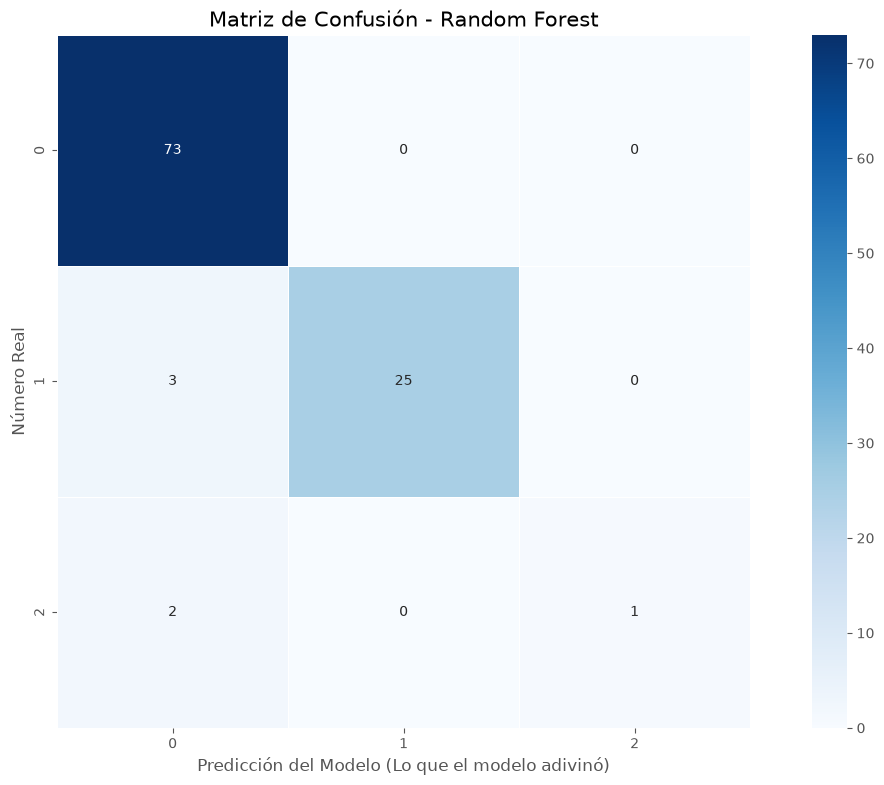

In [65]:
plt.figure(figsize=(16, 9))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=range(3), yticklabels=range(3),
    linewidths=.5, square=True
)
plt.title('Matriz de Confusión - Random Forest', size=15)
plt.ylabel('Número Real', size=12)
plt.xlabel('Predicción del Modelo (Lo que el modelo adivinó)', size=12)
plt.show()